# Chapter 2: Market Regimes and Sectors

*Do sectors behave the same way in bull, neutral, bear and recovering markets, or does the regime reshape everything?*

Sector analysis on the whole period assumes a stable market, but conditions keep changing. This chapter labels every day with a **market regime** taken from the S&P 500 (SPY), then compares sector **returns**, **volatility** and **correlations** across regimes.

- **Inputs:** `data_processed/stocks_sect.parquet` (sector table) and `data_processed/etfs_clean.parquet` (SPY prices).
- **Output:** the 15 Chapter 2 figures of the website, in `website/figures/chapter2/`.

Each figure is drawn twice: a light version shown in this notebook, and a dark transparent version saved for the website.

**Contents**
1. Setup
2. Sector series
3. Market regimes
4. Static view (no regime)
5. Sector returns by regime
6. Sector correlations by regime
7. Most volatile sectors by regime
8. Numbers quoted in the website text

## 1. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

from src.chapters.chapter2 import (
    REGIMES,
    clustered,
    plot_bars,
    plot_barh,
    plot_corr_heatmap,
    plot_line,
    rolling_avg_corr,
    spy_regimes,
)
from src.utils.figures import site_figure
from src.utils.sector_panel import first_date_all_sectors, sector_returns, sector_series, stocks_per_sector

PROCESSED_DIR = Path("data_processed")
FIG_SECTION = "chapter2"

END_DATE = "2020-04-01"       # last date of the price data
MIN_STOCKS_PER_SECTOR = 5     # start when every sector has at least 5 stocks (same rule as Chapter 1)
BEAR_THRESHOLD = -0.20        # SPY 20% or more below its peak
NEUTRAL_THRESHOLD = -0.05     # SPY between 5% and 20% below its peak
ROLLING_WINDOW = 60           # days for the rolling average correlation
VOL_COLUMN = "WeightedVol20"  # 20-day sector volatility
TOP_N_VOLATILE = 8            # sectors shown in the "most volatile" charts

## 2. Sector series

One daily series per sector, from `stocks_sect.parquet` (weights are each stock's share of the sector's dollar volume that day):

- **return:** weighted average of its stocks' daily returns;
- **volatility:** weighted average of its stocks' 20-day volatility.

In [2]:
stocks_sect = pd.read_parquet(
    PROCESSED_DIR / "stocks_sect.parquet",
    columns=["Date", "Symbol", "Sector", "Return", "Weight", VOL_COLUMN],
)
returns = sector_returns(stocks_sect)
volatility = sector_series(stocks_sect, VOL_COLUMN)
stock_counts = stocks_per_sector(stocks_sect)

## 3. Market regimes

Each day gets a regime from SPY's **drawdown**, its distance below its highest price so far:

| Regime | SPY drawdown |
|---|---|
| Bull | less than 5% below its peak |
| Neutral | 5% to 20% below its peak |
| Bear | 20% or more below its peak, **falling**: from the peak down to the bottom of the decline |
| Recovery | 20% or more below its peak, **rising**: after the bottom, until SPY is back within 20% of its peak |

A drawdown rule is transparent and has no fitted parameters. Bear and Recovery are split because a level alone mixes two opposite markets: about two thirds of the days 20% below the peak come *after* the bottom, while the market is rebounding strongly. Averaging them together would hide both the crash and the rebound.

Finding the bottom uses hindsight (the whole decline must be known). That is fine to describe the past, but this labelling could not be used as a trading signal (Chapter 6 uses a different rule).

The study period starts when every sector has at least `MIN_STOCKS_PER_SECTOR` stocks and SPY has prices.

In [3]:
spy = pd.read_parquet(PROCESSED_DIR / "etfs_clean.parquet", columns=["Date", "Symbol", "Adj Close"], filters=[("Symbol", "==", "SPY")])
regimes = spy_regimes(spy.set_index("Date")["Adj Close"], BEAR_THRESHOLD, NEUTRAL_THRESHOLD)

start = max(first_date_all_sectors(stock_counts, MIN_STOCKS_PER_SECTOR), regimes.index.min())
dates = returns.loc[start:END_DATE].index.intersection(regimes.index)
returns, volatility, regime = returns.loc[dates], volatility.loc[dates], regimes.loc[dates, "Regime"]

print(f"Study period: {dates.min().date()} → {dates.max().date()} ({len(dates)} days, {returns.shape[1]} sectors)")
regime.value_counts().reindex(REGIMES).rename("days").to_frame().assign(share=lambda d: (d["days"] / d["days"].sum()).round(3))

Study period: 1993-01-29 → 2020-04-01 (6843 days, 11 sectors)


,days,share
Regime,,
Bear,464,0.068
Recovery,923,0.135
Neutral,1818,0.266
Bull,3638,0.532


## 4. Static view (no regime)

### 4.1 Sector correlations over the whole period

Saved website/figures/chapter2/static_correlation.png


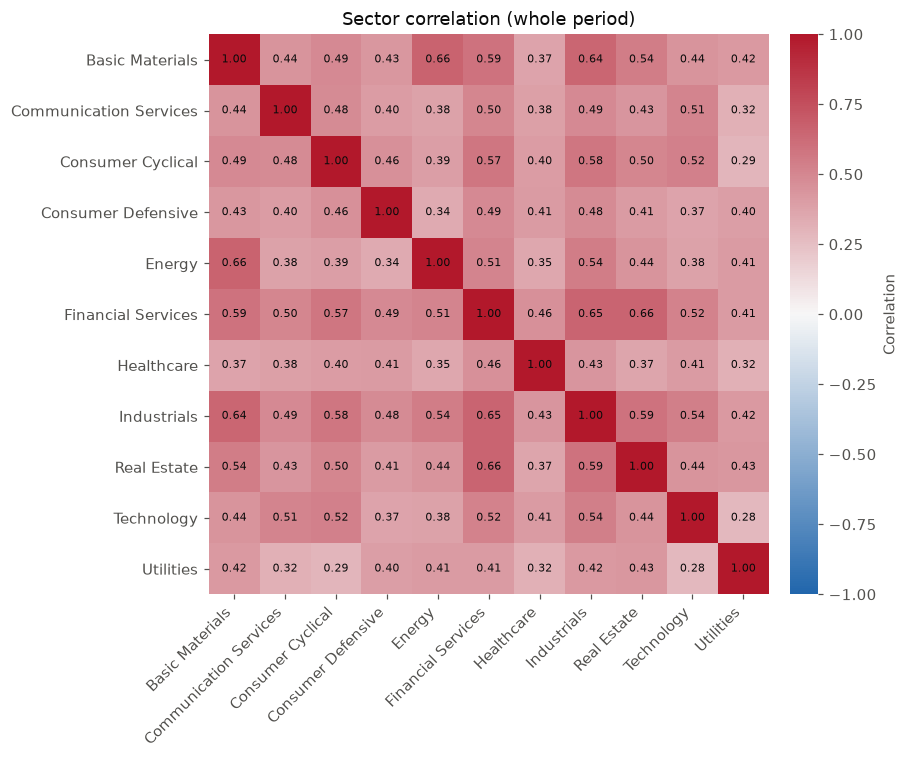

In [4]:
corr_static = returns.corr()
site_figure(plot_corr_heatmap, FIG_SECTION, "static_correlation", corr=corr_static, title="Sector correlation (whole period)");

### 4.2 Average sector correlation over time

Each point is the average correlation between all pairs of sectors over the previous 60 trading days. High values mean sectors move together and diversification across sectors helps less.

In [5]:
avg_corr = rolling_avg_corr(returns, ROLLING_WINDOW)
site_figure(plot_line, FIG_SECTION, "rolling_avg_correlation", series=avg_corr,
            title=f"Average sector correlation ({ROLLING_WINDOW}-day rolling)", ylabel="Average correlation");

Saved website/figures/chapter2/rolling_avg_correlation.png


### 4.3 Sector volatility across regimes

Average 20-day sector volatility, over all sectors and days of each regime.

In [6]:
vol_long = volatility.stack().rename("vol").reset_index().merge(regime.rename("Regime").reset_index(), on="Date")
vol_by_regime = vol_long.groupby("Regime", observed=True)["vol"].mean().reindex(REGIMES)
site_figure(plot_bars, FIG_SECTION, "volatility_by_regime", values=vol_by_regime,
            title="Sector volatility across market regimes", ylabel="Average sector volatility (20d)");

Saved website/figures/chapter2/volatility_by_regime.png


## 5. Sector returns by regime

Average daily return of each sector over the days of each regime.

In [7]:
avg_returns = returns.groupby(regime, observed=True).mean().reindex(REGIMES)

for r in REGIMES:
    site_figure(plot_barh, FIG_SECTION, f"returns_{r.lower()}", values=avg_returns.loc[r],
                title=f"Average sector return — {r} regime", xlabel="Average daily return");

Saved website/figures/chapter2/returns_bear.png
Saved website/figures/chapter2/returns_recovery.png
Saved website/figures/chapter2/returns_neutral.png
Saved website/figures/chapter2/returns_bull.png


## 6. Sector correlations by regime

Correlations computed on the days of each regime only, with sectors ordered by hierarchical clustering (average linkage on 1 − correlation) so that sectors that move together sit next to each other.

In [8]:
corr_by_regime = {r: clustered(returns[regime == r].corr()) for r in REGIMES}

for r in REGIMES:
    site_figure(plot_corr_heatmap, FIG_SECTION, f"correlation_{r.lower()}", corr=corr_by_regime[r],
                title=f"Clustered sector correlation — {r} regime");

Saved website/figures/chapter2/correlation_bear.png
Saved website/figures/chapter2/correlation_recovery.png
Saved website/figures/chapter2/correlation_neutral.png
Saved website/figures/chapter2/correlation_bull.png


## 7. Most volatile sectors by regime

Average 20-day volatility of each sector during each regime, top `TOP_N_VOLATILE` sectors.

In [9]:
vol_by_sector = volatility.groupby(regime, observed=True).mean().reindex(REGIMES)

for r in REGIMES:
    top = vol_by_sector.loc[r].sort_values(ascending=False).head(TOP_N_VOLATILE)
    site_figure(plot_bars, FIG_SECTION, f"top_volatility_{r.lower()}", values=top,
                title=f"Most volatile sectors during {r} markets", ylabel="Average sector volatility (20d)");

Saved website/figures/chapter2/top_volatility_bear.png
Saved website/figures/chapter2/top_volatility_recovery.png
Saved website/figures/chapter2/top_volatility_neutral.png
Saved website/figures/chapter2/top_volatility_bull.png


## 8. Numbers quoted in the website text

The Chapter 2 text in `website/index.html` describes these rankings and levels. After a new run, update the text with them.

In [10]:
pd.concat(
    {
        "avg daily return": avg_returns.T,
        "avg 20d volatility": vol_by_sector.T,
    },
    axis=1,
).round(4)

avg daily return                           \
Regime                             Bear Recovery Neutral    Bull   
Sector                                                             
Basic Materials                 -0.0018   0.0025  0.0005  0.0016   
Communication Services          -0.0019   0.0025  0.0003  0.0026   
Consumer Cyclical               -0.0013   0.0027  0.0002  0.0029   
Consumer Defensive              -0.0013   0.0006 -0.0002  0.0012   
Energy                          -0.0019   0.0016  0.0005  0.0016   
Financial Services              -0.0033   0.0022 -0.0003  0.0020   
Healthcare                      -0.0019   0.0006  0.0001  0.0028   
Industrials                     -0.0026   0.0020  0.0000  0.0020   
Real Estate                     -0.0032   0.0021  0.0004  0.0013   
Technology                      -0.0036   0.0024 -0.0002  0.0031   
Utilities                       -0.0035   0.0014  0.0004  0.0012   

                       avg 20d volatility                           
Regime                               Bear Recovery Neutral    Bull  
Sector                                                              
Basic Materials                    0.0373   0.0260  0.0244  0.0190  
Communication Services             0.0317   0.0234  0.0242  0.0192  
Consumer Cyclical                  0.0351   0.0250  0.0271  0.0221  
Consumer Defensive                 0.0227   0.0150  0.0172  0.0156  
Energy                             0.0337   0.0210  0.0234  0.0193  
Financial Services                 0.0371   0.0235  0.0212  0.0165  
Healthcare                         0.0275   0.0192  0.0213  0.0200  
Industrials                        0.0309   0.0218  0.0224  0.0182  
Real Estate                        0.0340   0.0223  0.0190  0.0147  
Technology                         0.0418   0.0244  0.0278  0.0228  
Utilities                          0.0261   0.0149  0.0142  0.0114

In [11]:
upper = np.triu_indices(returns.shape[1], 1)
pd.DataFrame({
    "days": regime.value_counts().reindex(REGIMES),
    "avg sector volatility (20d)": vol_by_regime,
    "avg pairwise correlation": pd.Series({r: corr_by_regime[r].values[upper].mean() for r in REGIMES}),
}).round(4)

,days,avg sector volatility (20d),avg pairwise correlation
Bear,464,0.0325,0.6677
Recovery,923,0.0215,0.5691
Neutral,1818,0.0220,0.4591
Bull,3638,0.0181,0.2747
